# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

(16814, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   sale_date                    16814 non-null  object
 1   sale_price                   16814 non-null  int64 
 2   house_square_feet            16814 non-null  int64 
 3   attic_finished_square_feet   16814 non-null  int64 
 4   basement_square_feet         16814 non-null  int64 
 5   attached_garage_square_feet  16814 non-null  int64 
 6   detached_garage_square_feet  16814 non-null  int64 
 7   fireplaces                   16814 non-null  int64 
 8   hvac_description             16807 non-null  object
 9   exterior                     16813 non-null  object
 10  interior                     16807 non-null  object
 11  stories                      16814 non-null  int64 
 12  roof_cover                   16806 non-null  object
 13  year_built         

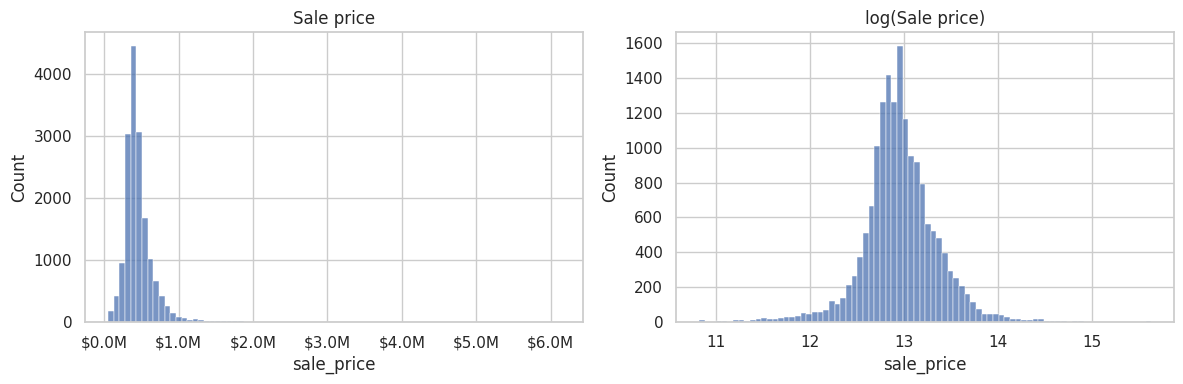

count       16,684
mean       461,845
std        235,233
min         50,000
25%        348,750
50%        417,000
75%        523,693
max      6,130,000
Name: sale_price, dtype: object


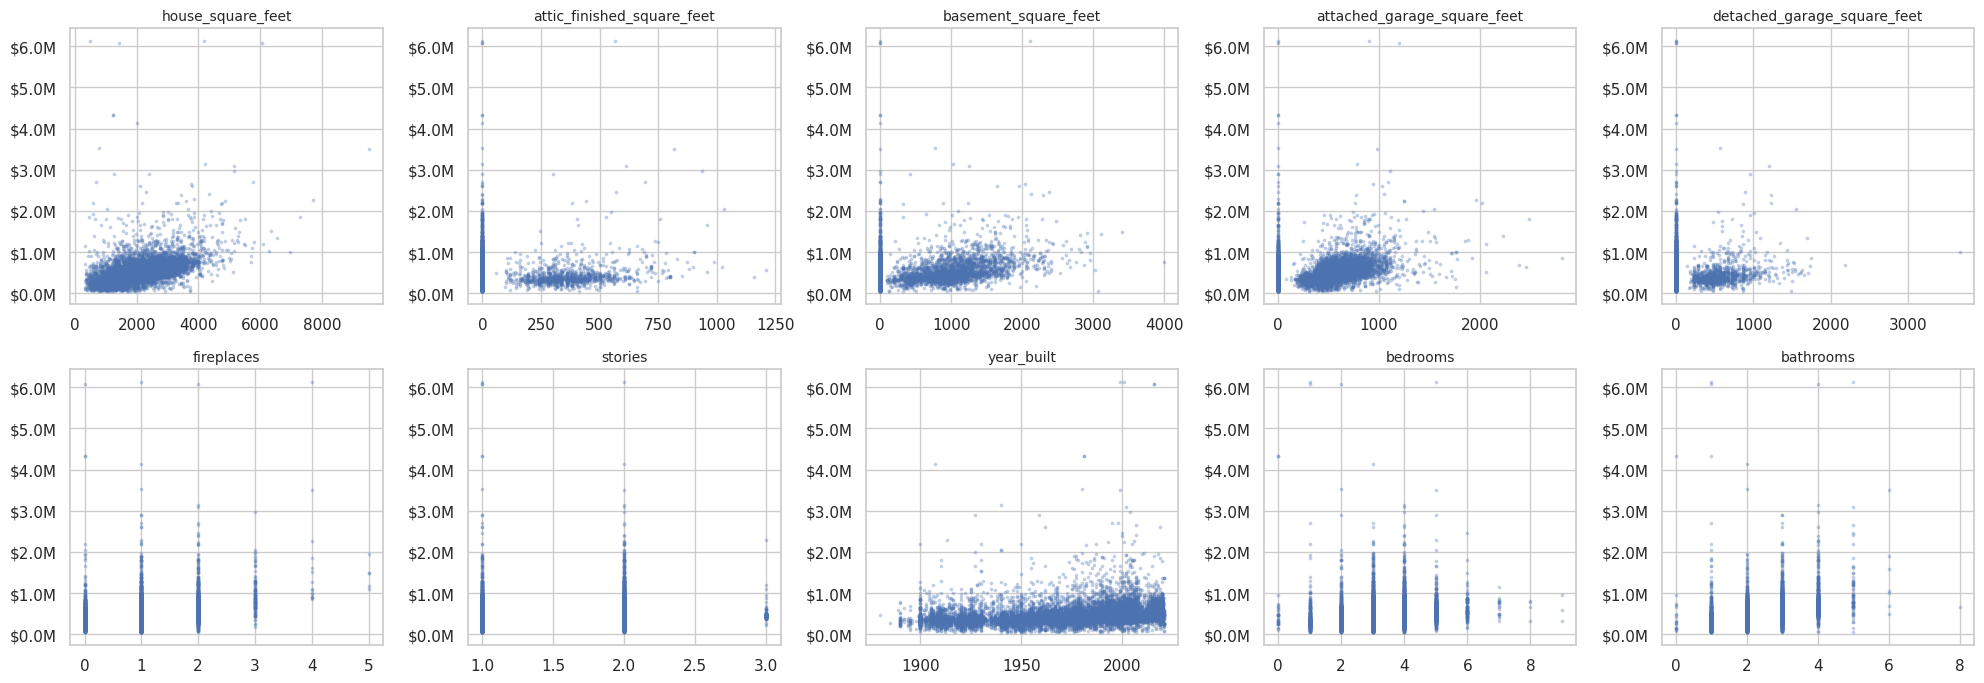

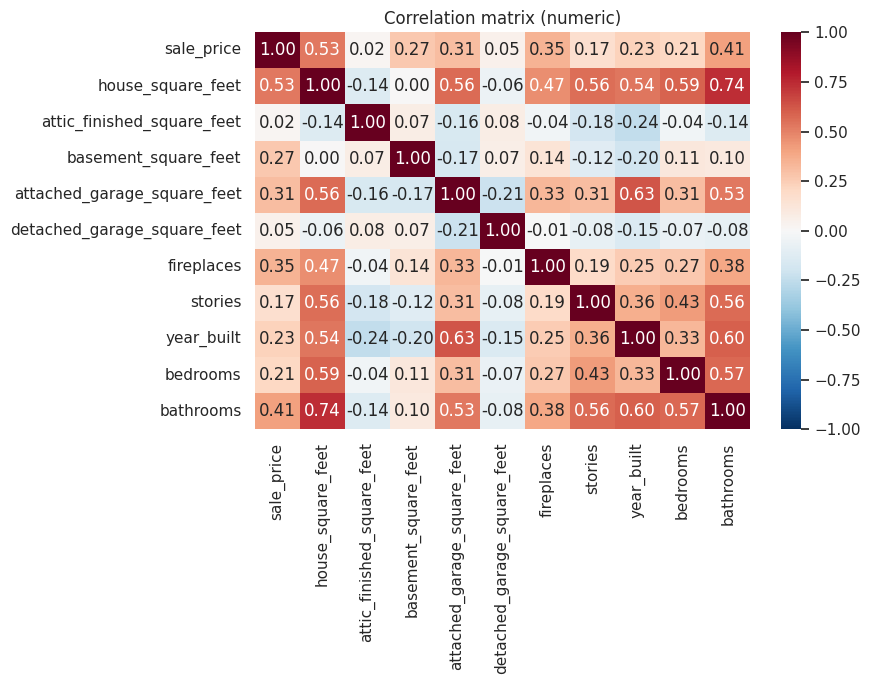

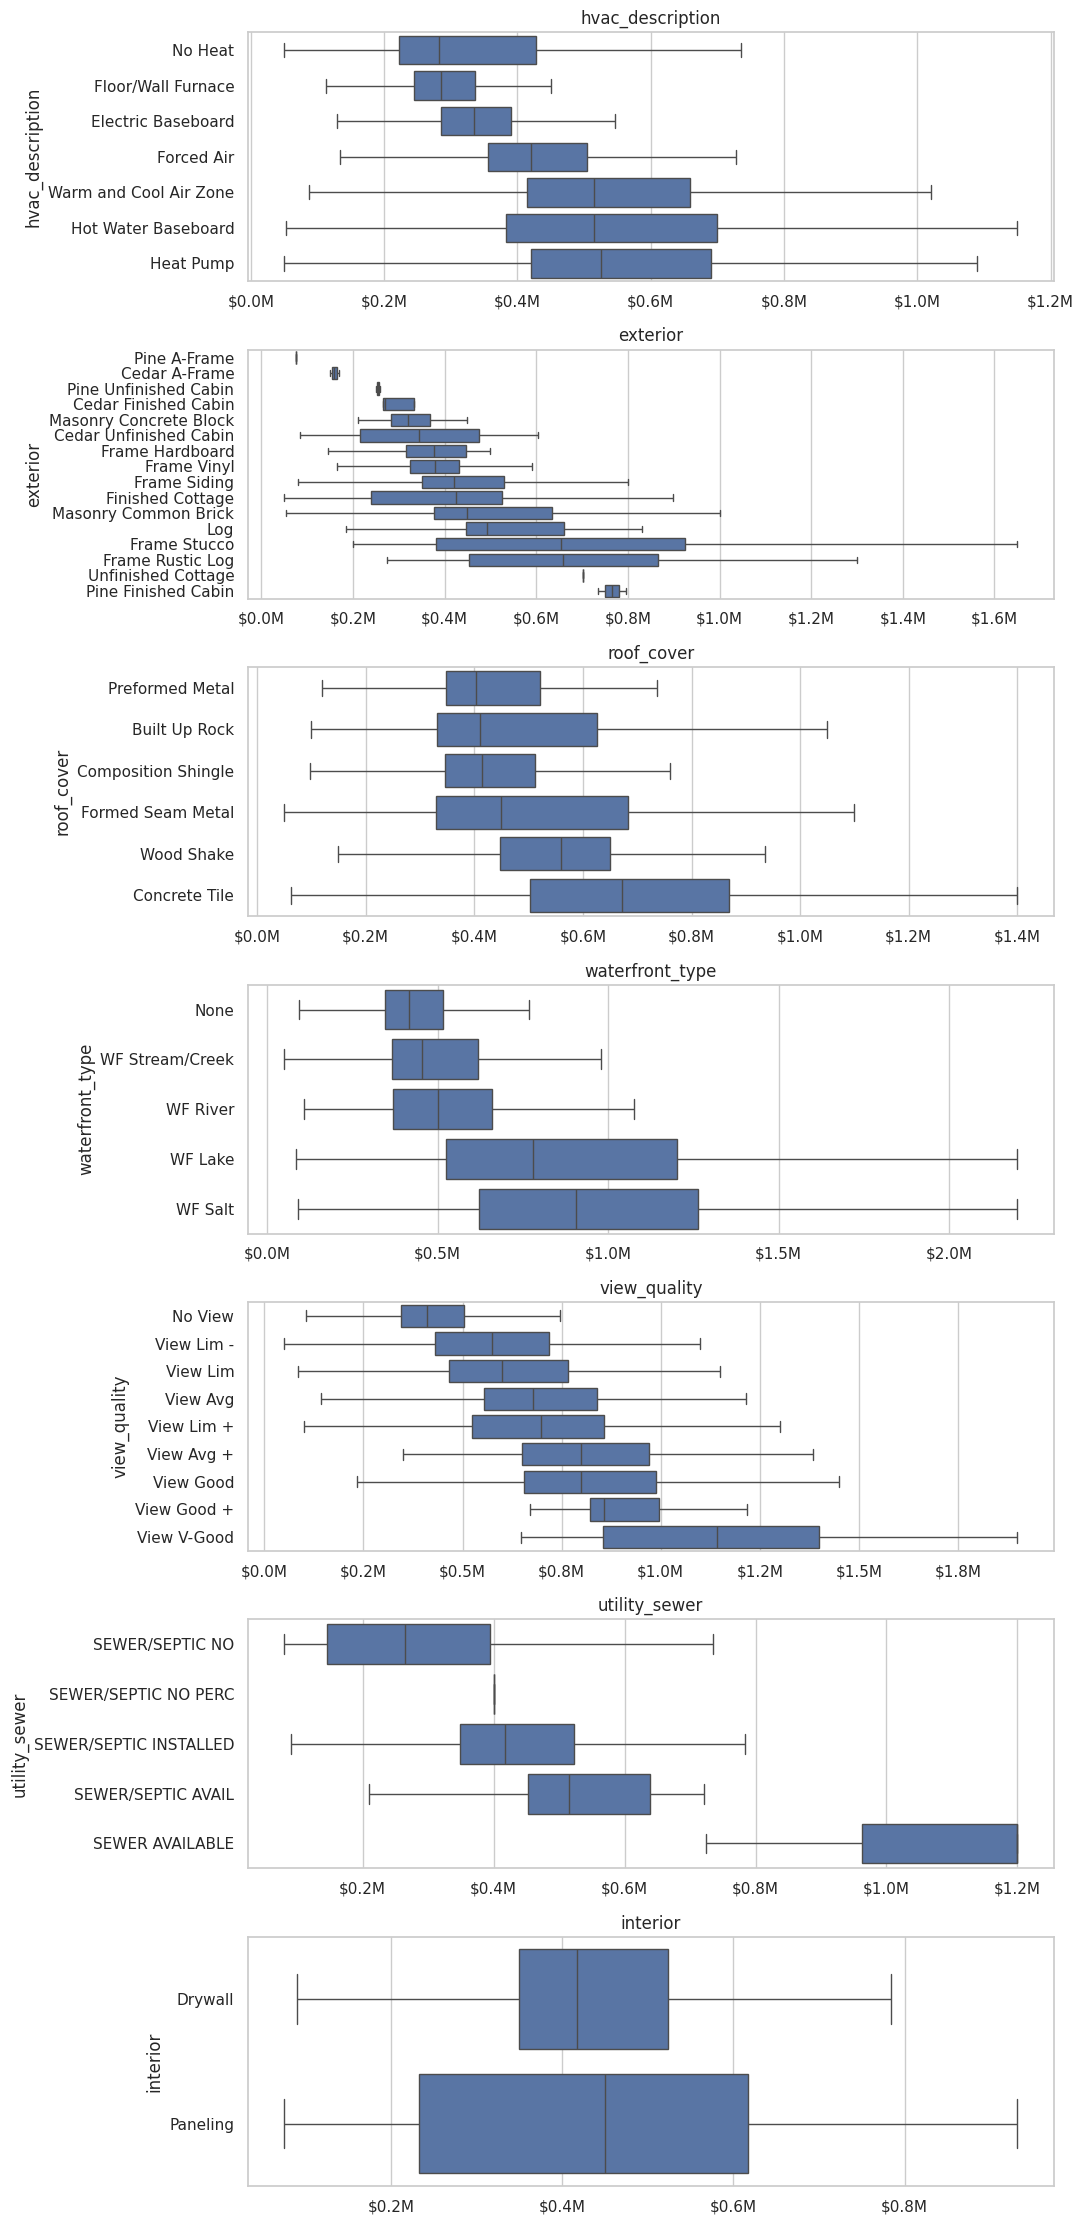

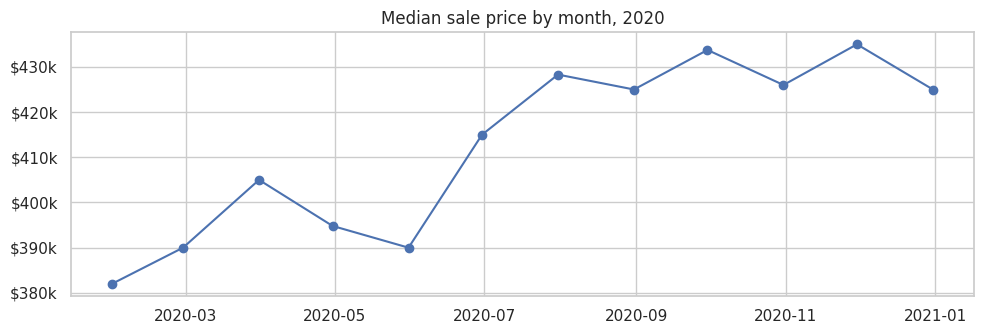

In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

URL = "https://raw.githubusercontent.com/elijahschoeniger-cpu/L02-hedonic-pricing/main/data/pierce_county_house_sales.csv"
df_raw = pd.read_csv(URL)
print(df_raw.shape)
df_raw.head()

#Q1


df_raw.info()
df_raw.isna().sum().sort_values(ascending=False)
df_raw.describe().T

for c in ["hvac_description", "exterior", "interior", "roof_cover",
          "waterfront_type", "view_quality", "utility_sewer"]:
    print(f"\n--- {c} ---")
    print(df_raw[c].value_counts(dropna=False))


# - `waterfront_type`~97% missing and `view_quality`~95% missing aren't really missing: NaN means *no waterfront* / *no view*.
# sale prices as low as 2000 dollars illogical
#46 duplicate rows


df = df_raw.copy()
n0 = len(df)
log = []

def drop(mask, why):
    global df
    k = int(mask.sum())
    df = df[~mask]
    log.append((why, k))

drop(df.duplicated(), "exact duplicate rows")
drop(df["sale_price"] < 50_000, "sale_price < $50k (likely non-market transfer)")
drop(df["house_square_feet"] < 300, "house_square_feet < 300 (data error)")
drop(df["stories"] == 0, "stories == 0 (data error)")
drop(df["bedrooms"] > 12, "bedrooms > 12 (data error)")

df["sale_date"] = pd.to_datetime(df["sale_date"])
df["hvac_description"] = df["hvac_description"].replace({
    "Floor Wall Furnace": "Floor/Wall Furnace",
    "Electric": "Electric Baseboard",
})
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("No View")
df = df.reset_index(drop=True)
df.isna().sum().sum()


fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["sale_price"], bins=80, ax=ax[0])
ax[0].set_title("Sale price")
ax[0].xaxis.set_major_formatter(lambda x, _: f"${x/1e6:.1f}M")
sns.histplot(np.log(df["sale_price"]), bins=80, ax=ax[1])
ax[1].set_title("log(Sale price)")
plt.tight_layout(); plt.show()
print(df["sale_price"].describe().apply(lambda x: f"{x:,.0f}"))
#price seems to be strongly right skewed. Might be important for later steps, log dist is symmetric.


num_cols = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet",
            "attached_garage_square_feet", "detached_garage_square_feet",
            "fireplaces", "stories", "year_built", "bedrooms", "bathrooms"]

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for c, ax in zip(num_cols, axes.flat):
    ax.scatter(df[c], df["sale_price"], s=3, alpha=0.25)
    ax.set_title(c, fontsize=10)
    ax.yaxis.set_major_formatter(lambda y, _: f"${y/1e6:.1f}M")
plt.tight_layout(); plt.show()

corr = df[["sale_price"] + num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix (numeric)")
plt.tight_layout(); plt.show()
corr["sale_price"].drop("sale_price").sort_values(ascending=False)


cat_cols = ["hvac_description", "exterior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer", "interior"]
fig, axes = plt.subplots(len(cat_cols), 1, figsize=(11, 3.2 * len(cat_cols)))
for c, ax in zip(cat_cols, axes):
    order = df.groupby(c)["sale_price"].median().sort_values().index
    sns.boxplot(data=df, y=c, x="sale_price", order=order, ax=ax, showfliers=False)
    ax.set_xlabel(""); ax.set_title(c)
    ax.xaxis.set_major_formatter(lambda x, _: f"${x/1e6:.1f}M")
plt.tight_layout(); plt.show()

# Waterfront and views carry large premiums. Many of the exterior categories are


monthly = df.set_index("sale_date")["sale_price"].resample("ME").median()
plt.figure(figsize=(10, 3.5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Median sale price by month, 2020")
plt.gca().yaxis.set_major_formatter(lambda y, _: f"${y/1e3:.0f}k")
plt.tight_layout(); plt.show()




## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]